In [1]:
import tensorflow as tf
print(tf.__version__)
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import sys
import sklearn
from sklearn import metrics
import os
import pandas as pd
import time
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import logging
logging.disable(30)
from collections import  Counter
import math
import random
from fitter import Fitter
random_seed =3407
tf.random.set_seed(random_seed )
os.environ['TF_DETERMINISTIC_OPS'] = '1'
print('ala')

2.9.0


D:\Anaconda3\lib\site-packages\sklearn\linear_model\least_angle.py:30: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  method='lar', copy_X=True, eps=np.finfo(np.float).eps,
D:\Anaconda3\lib\site-packages\sklearn\linear_model\least_angle.py:167: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  method='lar', copy_X=True, eps=np.finfo(np.float).

ala


In [2]:

source_data=np.load(r"48kcwru_data.npy")
source_label=np.load(r"48kcwru_label.npy")

target_data=np.load(r"seu2_data.npy")
target_label=np.load(r"seu2_label.npy")

source_data.shape,source_label.shape,target_data.shape,target_label.shape


((4000, 3072), (4000, 4), (4000, 3072), (4000, 4))

In [3]:

source_data=(source_data-source_data.min(axis=1).reshape((len(source_data),1)))/(source_data.max(axis=1).reshape((len(source_data),1))-source_data.min(axis=1).reshape((len(source_data),1)))
target_data=(target_data-target_data.min(axis=1).reshape((len(target_data),1)))/(target_data.max(axis=1).reshape((len(target_data),1))-target_data.min(axis=1).reshape((len(target_data),1)))

In [4]:

source_data=tf.expand_dims(source_data,axis=-1)
target_data=tf.expand_dims(target_data,axis=-1)

In [5]:

train_dataset=tf.data.Dataset.from_tensor_slices((source_data,target_data,source_label,target_label))
train_dataset=train_dataset.shuffle(4000).batch(128,drop_remainder=True)

test_dataset=tf.data.Dataset.from_tensor_slices((source_data,target_data,source_label,target_label))
test_dataset=test_dataset.batch(4000,drop_remainder=True)

In [6]:

def Model():
    input_1=tf.keras.Input(shape=(3072,1))

    x=tf.keras.layers.Conv1D(filters=16,kernel_size=64,strides=16,activation='relu',padding='same')(input_1)
    x=tf.keras.layers.BatchNormalization()(x)
    x=tf.keras.layers.MaxPooling1D(pool_size=2,strides=2,padding='same')(x)

    x=tf.keras.layers.Conv1D(filters=32,kernel_size=3,strides=1,activation='relu',padding='same')(x)
    x=tf.keras.layers.BatchNormalization()(x)
    x=tf.keras.layers.MaxPooling1D(pool_size=2,strides=2,padding='same')(x)

    x=tf.keras.layers.Conv1D(filters=64,kernel_size=3,strides=1,activation='relu',padding='same')(x)
    x=tf.keras.layers.BatchNormalization()(x)
    x=tf.keras.layers.MaxPooling1D(pool_size=2,strides=2,padding='same')(x)

    x=tf.keras.layers.Conv1D(filters=128,kernel_size=3,strides=1,activation='relu',padding='same')(x)
    x=tf.keras.layers.BatchNormalization()(x)
    x=tf.keras.layers.MaxPooling1D(pool_size=2,strides=2,padding='same')(x)

    x=tf.keras.layers.Conv1D(filters=256,kernel_size=3,strides=1,activation='relu',padding='same')(x)
    x=tf.keras.layers.BatchNormalization()(x)
    x=tf.keras.layers.MaxPooling1D(pool_size=2,strides=2,padding='same')(x)

    x=tf.keras.layers.GlobalAveragePooling1D()(x)

    y1=tf.keras.layers.Dense(128,activation='relu')(x)
    y2=tf.keras.layers.Dense(4)(y1)

    model=tf.keras.Model(inputs=input_1,outputs=[y1,y2])
    
    return model

model=Model()
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 3072, 1)]         0         
                                                                 
 conv1d (Conv1D)             (None, 192, 16)           1040      
                                                                 
 batch_normalization (BatchN  (None, 192, 16)          64        
 ormalization)                                                   
                                                                 
 max_pooling1d (MaxPooling1D  (None, 96, 16)           0         
 )                                                               
                                                                 
 conv1d_1 (Conv1D)           (None, 96, 32)            1568      
                                                                 
 batch_normalization_1 (Batc  (None, 96, 32)           128   

In [7]:

pre_optimizer=tf.keras.optimizers.Adam(learning_rate=0.001)
optimizer=tf.keras.optimizers.Adam(learning_rate=0.001)             
loss_func=tf.keras.losses.CategoricalCrossentropy(from_logits=True) 

In [8]:

def mix_rbf_mmsd(X, Y, sigmas=(1,), wts=None, biased=True):
    K_XX, K_XY, K_YY, d = _mix_rbf_kernel(X, Y, sigmas, wts)
    return _mmsd(K_XX, K_XY, K_YY, const_diagonal=d, biased=biased)


def _mix_rbf_kernel(X, Y, sigmas, wts=None):
    if wts is None:
        wts = [1] * len(sigmas)

    XX = tf.matmul(X, X, transpose_b=True)
    XY = tf.matmul(X, Y, transpose_b=True)
    YY = tf.matmul(Y, Y, transpose_b=True)

    X_sqnorms = tf.linalg.diag_part(XX)
    Y_sqnorms = tf.linalg.diag_part(YY)

    r = lambda x: tf.expand_dims(x, 0)
    c = lambda x: tf.expand_dims(x, 1)

    K_XX, K_XY, K_YY = 0, 0, 0
    for sigma, wt in zip(sigmas, wts):
        gamma = 1 / (2 * sigma**2)
        K_XX += wt * tf.exp(-gamma * (-2 * XX + c(X_sqnorms) + r(X_sqnorms)))
        K_XY += wt * tf.exp(-gamma * (-2 * XY + c(X_sqnorms) + r(Y_sqnorms)))
        K_YY += wt * tf.exp(-gamma * (-2 * YY + c(Y_sqnorms) + r(Y_sqnorms)))
    return K_XX, K_XY, K_YY, tf.reduce_sum(wts)
    

def _mmsd(K_XX, K_XY, K_YY, const_diagonal=False, biased=False):
    m = tf.cast(K_XX.get_shape()[0], tf.float32)
    n = tf.cast(K_YY.get_shape()[0], tf.float32)
    
    C_K_XX=tf.pow(K_XX,2)
    C_K_YY=tf.pow(K_YY,2)
    C_K_XY=tf.pow(K_XY,2)


    if biased:
        mmsd = (tf.reduce_sum(C_K_XX) / (m * m)
              + tf.reduce_sum(C_K_YY) / (n * n)
              - 2 * tf.reduce_sum(C_K_XY) / (m * n))
    else:
        if const_diagonal is not False:
            trace_X = m * const_diagonal
            trace_Y = n * const_diagonal
        else:
            trace_X = tf.linalg.trace(C_K_XX)
            trace_Y = tf.linalg.trace(C_K_YY)

        mmsd = ((tf.reduce_sum(C_K_XX) - trace_X) / ((m-1) * m)
              + (tf.reduce_sum(C_K_YY) - trace_Y) / ((n-1) * n)
              - 2 * tf.reduce_sum(C_K_XY) / (m* n))
    return mmsd

In [9]:

def mmsd_rbf_loss(X1,X2, bandwidths=[3]):
    kernel_loss = mix_rbf_mmsd(X1,X2, sigmas=bandwidths)
    return kernel_loss

In [10]:

clc_loss=tf.keras.metrics.Mean('clc_loss')                       
mmsd_loss=tf.keras.metrics.Mean('mvd_loss')

train_accuracy=tf.keras.metrics.CategoricalAccuracy('train_accuracy')
test_accuracy=tf.keras.metrics.CategoricalAccuracy('test_accuracy')

train_acc=[]
test_acc=[]
clc_loss_=[]
mmsd_loss_=[]

In [11]:

def train_step(model, source_data,target_data,source_label,target_label):
    u=1
    with tf.GradientTape() as t:
        out1,output1 = model(source_data,training = True)                              
        out2,output2 = model(target_data,training = True)                               
        loss_step =loss_func(source_label,output1) + u*mmsd_rbf_loss(output1,output2)      
    grads = t.gradient(loss_step, model.trainable_variables)
    
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    
    mmsd_loss(u*mmsd_rbf_loss(output1,output2))
    clc_loss(loss_func(source_label,output1))
    train_accuracy(source_label,output1)
    test_accuracy(target_label,output2)

    
def train(epochs):
    for epoch in range(epochs):
        for (batch, (source_data,target_data,source_label,target_label)) in enumerate(train_dataset):
            train_step(model,source_data,target_data,source_label,target_label)
        train_acc.append(train_accuracy.result())
        mmsd_loss_.append(mmsd_loss.result())
        clc_loss_.append(clc_loss.result())
        test_acc.append(test_accuracy.result())
        
        print('Epoch{}, mmsd_loss is {:.5f}, clc_loss is {:.5f}, train_accuracy is {:.5f},test_accuracy is {:.5f}'.format(epoch+1,
                                                                                          mmsd_loss.result(),
                                                                                          clc_loss.result(),           
                                                                                          train_accuracy.result(),
                                                                                          test_accuracy.result()))
        
        mmsd_loss.reset_states()
        clc_loss.reset_states()
        train_accuracy.reset_states()
        test_accuracy.reset_states()

In [12]:

epochs=100
train(epochs)

Epoch1, mmsd_loss is 0.08007, clc_loss is 0.12726, train_accuracy is 0.95993,test_accuracy is 0.60711
Epoch2, mmsd_loss is 0.02631, clc_loss is 0.00367, train_accuracy is 0.99950,test_accuracy is 0.78503
Epoch3, mmsd_loss is 0.02138, clc_loss is 0.00181, train_accuracy is 0.99950,test_accuracy is 0.83543
Epoch4, mmsd_loss is 0.01768, clc_loss is 0.00114, train_accuracy is 1.00000,test_accuracy is 0.86744
Epoch5, mmsd_loss is 0.01651, clc_loss is 0.00094, train_accuracy is 0.99975,test_accuracy is 0.89189
Epoch6, mmsd_loss is 0.01640, clc_loss is 0.00085, train_accuracy is 0.99975,test_accuracy is 0.90348
Epoch7, mmsd_loss is 0.01591, clc_loss is 0.00041, train_accuracy is 1.00000,test_accuracy is 0.91860
Epoch8, mmsd_loss is 0.01497, clc_loss is 0.00034, train_accuracy is 1.00000,test_accuracy is 0.92540
Epoch9, mmsd_loss is 0.01386, clc_loss is 0.00022, train_accuracy is 1.00000,test_accuracy is 0.93145
Epoch10, mmsd_loss is 0.01405, clc_loss is 0.00029, train_accuracy is 1.00000,test

Epoch80, mmsd_loss is 0.00013, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch81, mmsd_loss is 0.00011, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch82, mmsd_loss is 0.00014, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch83, mmsd_loss is 0.00011, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch84, mmsd_loss is 0.00011, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch85, mmsd_loss is 0.00013, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch86, mmsd_loss is 0.00013, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch87, mmsd_loss is 0.00011, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch88, mmsd_loss is 0.00009, clc_loss is 0.00002, train_accuracy is 1.00000,test_accuracy is 1.00000
Epoch89, mmsd_loss is 0.00012, clc_loss is 0.00002, train_accuracy is 1.0

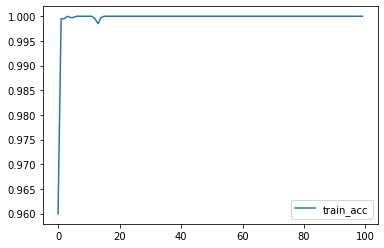

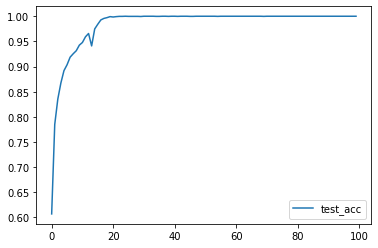

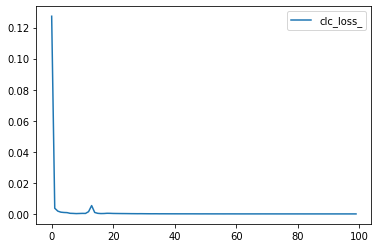

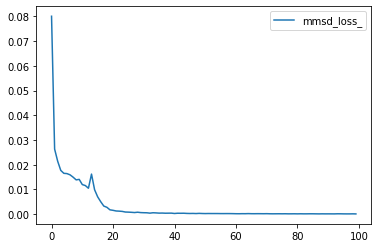

In [13]:

string=['train_acc','test_acc','clc_loss_','mmsd_loss_']
for i in string:
    plt.plot(eval(i),label=i)
    plt.legend()
    plt.show()

In [20]:
import tensorflow as tf

def transfer_learning_model():
    # Load the pre-trained model (base model)
    base_model = Model()  # Assuming the base model 'Model' is already defined

    # Freeze all convolutional layers (the first few layers)
    for layer in base_model.layers:
        if isinstance(layer, tf.keras.layers.Conv1D):
            layer.trainable = False

    # Modify the output layer of the base model to have 10 classes
    x = base_model.output[0]  # Use only the first output from base model (y1)
    x = tf.keras.layers.Dense(128, activation='relu')(x)  # Dense layer for further processing
    output = tf.keras.layers.Dense(10, activation='softmax')(x)  # 10 classes output

    # Create the new transfer learning model
    transfer_model = tf.keras.Model(inputs=base_model.input, outputs=output)

    # Compile the new model with Adam optimizer and categorical cross-entropy loss
    transfer_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                           loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False),
                           metrics=['accuracy'])

    # Print the summary of the transfer model to inspect it
    transfer_model.summary()

    return transfer_model

# Create the transfer learning model
transfer_model = transfer_learning_model()


Model: "model_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 3072, 1)]         0         
                                                                 
 conv1d_10 (Conv1D)          (None, 192, 16)           1040      
                                                                 
 batch_normalization_10 (Bat  (None, 192, 16)          64        
 chNormalization)                                                
                                                                 
 max_pooling1d_10 (MaxPoolin  (None, 96, 16)           0         
 g1D)                                                            
                                                                 
 conv1d_11 (Conv1D)          (None, 96, 32)            1568      
                                                                 
 batch_normalization_11 (Bat  (None, 96, 32)           128 

In [14]:

import tensorflow as tf

def transfer_learning_model():
    # Load the pre-trained model (base model)
    base_model = Model()  # Assuming the base model 'Model' is already defined

    # Freeze all convolutional layers (the first few layers)
    for layer in base_model.layers:
        if isinstance(layer, tf.keras.layers.Conv1D):
            layer.trainable = False

    # Modify the output layer of the base model to have 10 classes
    x = base_model.output[0]  # Use only the first output from base model (y1)
    x = tf.keras.layers.Dense(128, activation='relu')(x)  # Dense layer for further processing
    output = tf.keras.layers.Dense(4, activation='softmax')(x)  # 10 classes output

    # Create the new transfer learning model
    transfer_model = tf.keras.Model(inputs=base_model.input, outputs=output)

    # Compile the new model with Adam optimizer and categorical cross-entropy loss
    transfer_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                           loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False),
                           metrics=['accuracy'])

    # Print the summary of the transfer model to inspect it
    transfer_model.summary()

    return transfer_model

# Create the transfer learning model
transfer_model = transfer_learning_model()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 3072, 1)]         0         
                                                                 
 conv1d_5 (Conv1D)           (None, 192, 16)           1040      
                                                                 
 batch_normalization_5 (Batc  (None, 192, 16)          64        
 hNormalization)                                                 
                                                                 
 max_pooling1d_5 (MaxPooling  (None, 96, 16)           0         
 1D)                                                             
                                                                 
 conv1d_6 (Conv1D)           (None, 96, 32)            1568      
                                                                 
 batch_normalization_6 (Batc  (None, 96, 32)           128 

In [15]:
import scipy.io as scio
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# 1hp-data
normal = scio.loadmat('C-N.mat')['X098_DE_time']

B007 = scio.loadmat('Cb7.mat')['X119_DE_time']
B014 = scio.loadmat('Cb14.mat')['X186_DE_time']
B021 = scio.loadmat('Cb21.mat')['X223_DE_time']

IR007 = scio.loadmat('Ci7.mat')['X106_DE_time']
IR014 = scio.loadmat('Ci14.mat')['X170_DE_time']
IR021 = scio.loadmat('Ci21.mat')['X210_DE_time']

OR007 = scio.loadmat('Co7.mat')['X131_DE_time']
OR014 = scio.loadmat('Co14.mat')['X198_DE_time']
OR021 = scio.loadmat('Co21.mat')['X235_DE_time']

# 用滑窗截取，形成训练样本集
win_len = 3072  # 每个样本的大小（指含有的振动点数）
step = 200  # 滑窗截取时的步长

# 定义 data_sample 制作样本集的函数
def data_sample(data, win_len, step):
    i = 0
    data_sample = []  # 建立一个名字为 data_sample 的空白矩阵
    # 用滑窗截取
    while i < len(data) - win_len:
        data_sample.append(data[i:i + win_len])
        i = i + step
    return data_sample

# 应用制作数据样本的自定义函数 data_sample 生成数据样本
normal_sample = np.array(data_sample(normal, win_len, step))
normal_sample = normal_sample[:600, :, :]

IR007_sample = np.array(data_sample(IR007, win_len, step))
IR007_sample = IR007_sample[:600, :, :]

B007_sample = np.array(data_sample(B007, win_len, step))
B007_sample = B007_sample[:600, :, :]

OR007_sample = np.array(data_sample(OR007, win_len, step))
OR007_sample = OR007_sample[:600, :, :]

IR014_sample = np.array(data_sample(IR014, win_len, step))
IR014_sample = IR014_sample[:600, :, :]

B014_sample = np.array(data_sample(B014, win_len, step))
B014_sample = B014_sample[:600, :, :]

OR014_sample = np.array(data_sample(OR014, win_len, step))
OR014_sample = OR014_sample[:600, :, :]

IR021_sample = np.array(data_sample(IR021, win_len, step))
IR021_sample = IR021_sample[:600, :, :]

B021_sample = np.array(data_sample(B021, win_len, step))
B021_sample = B021_sample[:600, :, :]

OR021_sample = np.array(data_sample(OR021, win_len, step))
OR021_sample = OR021_sample[:600, :, :]

# 输出各故障类别的样本集大小
print('正常数据规模：', normal_sample.shape)
print('0.007英寸内圈故障的数据规模：', IR007_sample.shape)
print('0.021英寸内圈故障的数据规模：', IR021_sample.shape)
print('0.014英寸内圈故障的数据规模：', IR014_sample.shape)
print('0.07英寸外圈故障的数据规模：', OR007_sample.shape)
print('0.021英寸外圈故障的数据规模：', OR021_sample.shape)
print('0.014英寸外圈故障的数据规模：', OR014_sample.shape)
print('0.07英寸滚珠故障的数据规模：', B007_sample.shape)
print('0.021英寸滚珠故障的数据规模：', B021_sample.shape)
print('0.014英寸滚珠故障的数据规模：', B014_sample.shape)

# 制作分类标签
normal_label = [0 for i in range(normal_sample.shape[0])]  # 正常数据的 label 为 0
IR007_label = [1 for i in range(IR007_sample.shape[0])]  # 内圈 0.007，故障数据的 label 为 1
B007_label = [2 for i in range(B007_sample.shape[0])]
OR007_label = [3 for i in range(OR007_sample.shape[0])]
IR014_label = [4 for i in range(IR014_sample.shape[0])]  # 内圈 0.014，故障数据的 label 为 4
B014_label = [5 for i in range(B014_sample.shape[0])]
OR014_label = [6 for i in range(OR014_sample.shape[0])]
IR021_label = [7 for i in range(IR021_sample.shape[0])]  # 内圈 0.021，故障数据的 label 为 7
B021_label = [8 for i in range(B021_sample.shape[0])]
OR021_label = [9 for i in range(OR021_sample.shape[0])]

# 对应制作训练数据和标签数据
x_data = np.vstack((normal_sample, IR007_sample, B007_sample, OR007_sample, IR014_sample, B014_sample, OR014_sample, IR021_sample, B021_sample, OR021_sample))  # 按垂直方向（行顺序）堆叠数组构成一个新的数组
y_data = normal_label + IR007_label + B007_label + OR007_label + IR014_label + B014_label + OR014_label + IR021_label + B021_label + OR021_label
print(x_data.shape, 'x')

# 将标签 one-hot
y_data = to_categorical(y_data, num_classes=10)  # 将 label 转换为 one-hot

# Reshape x_data to remove the extra dimension and get the desired shape (samples, features)
x_data = x_data.reshape(x_data.shape[0], -1)  # Flatten the 3rd dimension

# Train-test split
BX_train, BX_test, By_train, By_test = train_test_split(x_data, y_data, test_size=0.2)

print('BX_train：', BX_train.shape)
print('BX_test：', BX_test.shape)
print('By_train：', By_train.shape)
print('By_test：', By_test.shape)


正常数据规模： (600, 3072, 1)
0.007英寸内圈故障的数据规模： (595, 3072, 1)
0.021英寸内圈故障的数据规模： (593, 3072, 1)
0.014英寸内圈故障的数据规模： (594, 3072, 1)
0.07英寸外圈故障的数据规模： (597, 3072, 1)
0.021英寸外圈故障的数据规模： (595, 3072, 1)
0.014英寸外圈故障的数据规模： (596, 3072, 1)
0.07英寸滚珠故障的数据规模： (592, 3072, 1)
0.021英寸滚珠故障的数据规模： (594, 3072, 1)
0.014英寸滚珠故障的数据规模： (596, 3072, 1)
(5952, 3072, 1) x
BX_train： (4761, 3072)
BX_test： (1191, 3072)
By_train： (4761, 10)
By_test： (1191, 10)


In [16]:
import scipy.io as scio
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# 2hp-data
normal = scio.loadmat('B-N.mat')['X099_DE_time']

B007 = scio.loadmat('Bb7.mat')['X120_DE_time']
B014 = scio.loadmat('Bb14.mat')['X187_DE_time']
B021 = scio.loadmat('Bb21.mat')['X224_DE_time']

IR007 = scio.loadmat('Bi7.mat')['X107_DE_time']
IR014 = scio.loadmat('Bi14.mat')['X171_DE_time']
IR021 = scio.loadmat('Bi21.mat')['X211_DE_time']

OR007 = scio.loadmat('Bo7.mat')['X132_DE_time']
OR014 = scio.loadmat('Bo14.mat')['X199_DE_time']
OR021 = scio.loadmat('Bo21.mat')['X236_DE_time']

# 用滑窗截取，形成训练样本集
win_len = 3072  # 每个样本的大小（指含有的振动点数）
step = 200  # 滑窗截取时的步长

# 定义 data_sample 制作样本集的函数
def data_sample(data, win_len, step):
    i = 0
    data_sample = []  # 建立一个名字为 data_sample 的空白矩阵
    # 用滑窗截取
    while i < len(data) - win_len:
        data_sample.append(data[i:i + win_len])
        i = i + step
    return data_sample

# 应用制作数据样本的自定义函数 data_sample 生成数据样本
normal_sample = np.array(data_sample(normal, win_len, step))
normal_sample = normal_sample[:600, :, :]

IR007_sample = np.array(data_sample(IR007, win_len, step))
IR007_sample = IR007_sample[:600, :, :]

B007_sample = np.array(data_sample(B007, win_len, step))
B007_sample = B007_sample[:600, :, :]

OR007_sample = np.array(data_sample(OR007, win_len, step))
OR007_sample = OR007_sample[:600, :, :]

IR014_sample = np.array(data_sample(IR014, win_len, step))
IR014_sample = IR014_sample[:600, :, :]

B014_sample = np.array(data_sample(B014, win_len, step))
B014_sample = B014_sample[:600, :, :]

OR014_sample = np.array(data_sample(OR014, win_len, step))
OR014_sample = OR014_sample[:600, :, :]

IR021_sample = np.array(data_sample(IR021, win_len, step))
IR021_sample = IR021_sample[:600, :, :]

B021_sample = np.array(data_sample(B021, win_len, step))
B021_sample = B021_sample[:600, :, :]

OR021_sample = np.array(data_sample(OR021, win_len, step))
OR021_sample = OR021_sample[:600, :, :]

# 输出各故障类别的样本集大小
print('正常数据规模：', normal_sample.shape)
print('0.007英寸内圈故障的数据规模：', IR007_sample.shape)
print('0.021英寸内圈故障的数据规模：', IR021_sample.shape)
print('0.014英寸内圈故障的数据规模：', IR014_sample.shape)
print('0.07英寸外圈故障的数据规模：', OR007_sample.shape)
print('0.021英寸外圈故障的数据规模：', OR021_sample.shape)
print('0.014英寸外圈故障的数据规模：', OR014_sample.shape)
print('0.07英寸滚珠故障的数据规模：', B007_sample.shape)
print('0.021英寸滚珠故障的数据规模：', B021_sample.shape)
print('0.014英寸滚珠故障的数据规模：', B014_sample.shape)

# 制作分类标签
normal_label = [0 for i in range(normal_sample.shape[0])]  # 正常数据的 label 为 0
IR007_label = [1 for i in range(IR007_sample.shape[0])]  # 内圈 0.007，故障数据的 label 为 1
B007_label = [2 for i in range(B007_sample.shape[0])]
OR007_label = [3 for i in range(OR007_sample.shape[0])]
IR014_label = [4 for i in range(IR014_sample.shape[0])]  # 内圈 0.014，故障数据的 label 为 4
B014_label = [5 for i in range(B014_sample.shape[0])]
OR014_label = [6 for i in range(OR014_sample.shape[0])]
IR021_label = [7 for i in range(IR021_sample.shape[0])]  # 内圈 0.021，故障数据的 label 为 7
B021_label = [8 for i in range(B021_sample.shape[0])]
OR021_label = [9 for i in range(OR021_sample.shape[0])]

# 对应制作训练数据和标签数据
x_data = np.vstack((normal_sample, IR007_sample, B007_sample, OR007_sample, IR014_sample, B014_sample, OR014_sample, IR021_sample, B021_sample, OR021_sample))  # 按垂直方向（行顺序）堆叠数组构成一个新的数组
y_data = normal_label + IR007_label + B007_label + OR007_label + IR014_label + B014_label + OR014_label + IR021_label + B021_label + OR021_label
print(x_data.shape, 'x')

# 将标签 one-hot
y_data = to_categorical(y_data, num_classes=10)  # 将 label 转换为 one-hot

# Reshape x_data to remove the extra dimension and get the desired shape (samples, features)
x_data = x_data.reshape(x_data.shape[0], -1)  # Flatten the 3rd dimension

# Train-test split
CX_train, CX_test, Cy_train, Cy_test = train_test_split(x_data, y_data, test_size=0.2)

print('CX_train：', CX_train.shape)
print('CX_test：', CX_test.shape)
print('Cy_train：', Cy_train.shape)
print('Cy_test：', Cy_test.shape)


正常数据规模： (600, 3072, 1)
0.007英寸内圈故障的数据规模： (596, 3072, 1)
0.021英寸内圈故障的数据规模： (594, 3072, 1)
0.014英寸内圈故障的数据规模： (594, 3072, 1)
0.07英寸外圈故障的数据规模： (592, 3072, 1)
0.021英寸外圈故障的数据规模： (597, 3072, 1)
0.014英寸外圈故障的数据规模： (594, 3072, 1)
0.07英寸滚珠故障的数据规模： (593, 3072, 1)
0.021英寸滚珠故障的数据规模： (596, 3072, 1)
0.014英寸滚珠故障的数据规模： (595, 3072, 1)
(5951, 3072, 1) x
CX_train： (4760, 3072)
CX_test： (1191, 3072)
Cy_train： (4760, 10)
Cy_test： (1191, 10)


In [17]:
import scipy.io as scio
import numpy as np
from tensorflow.keras.optimizers import Adam
from sklearn.manifold import TSNE
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.utils.np_utils import to_categorical

# 3hp-data
normal = scio.loadmat('A-N.mat')['X100_DE_time']

B007 = scio.loadmat('Ab7.mat')['X121_DE_time']
B014 = scio.loadmat('Ab14.mat')['X188_DE_time']
B021 = scio.loadmat('Ab21.mat')['X225_DE_time']

IR007 = scio.loadmat('Ai7.mat')['X108_DE_time']
IR014 = scio.loadmat('Ai14.mat')['X172_DE_time']
IR021 = scio.loadmat('Ai21.mat')['X212_DE_time']

OR007 = scio.loadmat('Ao7.mat')['X133_DE_time']
OR014 = scio.loadmat('Ao14.mat')['X200_DE_time']
OR021 = scio.loadmat('Ao21.mat')['X237_DE_time']

# 用滑窗截取，形成训练样本集
win_len = 3072  # 每个样本的大小（指含有的振动点数）
step = 200  # 滑窗截取时的步长

# 定义 data_sample 制作样本集的函数
def data_sample(data, win_len, step):
    i = 0
    data_sample = []  # 建立一个名字为 data_sample 的空白矩阵
    # 用滑窗截取
    while i < len(data) - win_len:
        data_sample.append(data[i:i + win_len])
        i = i + step
    return data_sample

# 应用制作数据样本的自定义函数 data_sample 生成数据样本
normal_sample = np.array(data_sample(normal, win_len, step))
normal_sample = normal_sample[:600, :, :]

IR007_sample = np.array(data_sample(IR007, win_len, step))
IR007_sample = IR007_sample[:600, :, :]

B007_sample = np.array(data_sample(B007, win_len, step))
B007_sample = B007_sample[:600, :, :]

OR007_sample = np.array(data_sample(OR007, win_len, step))
OR007_sample = OR007_sample[:600, :, :]

IR014_sample = np.array(data_sample(IR014, win_len, step))
IR014_sample = IR014_sample[:600, :, :]

B014_sample = np.array(data_sample(B014, win_len, step))
B014_sample = B014_sample[:600, :, :]

OR014_sample = np.array(data_sample(OR014, win_len, step))
OR014_sample = OR014_sample[:600, :, :]

IR021_sample = np.array(data_sample(IR021, win_len, step))
IR021_sample = IR021_sample[:600, :, :]

B021_sample = np.array(data_sample(B021, win_len, step))
B021_sample = B021_sample[:600, :, :]

OR021_sample = np.array(data_sample(OR021, win_len, step))
OR021_sample = OR021_sample[:600, :, :]

# 输出各故障类别的样本集大小
print('正常数据规模：', normal_sample.shape)
print('0.007英寸内圈故障的数据规模：', IR007_sample.shape)
print('0.021英寸内圈故障的数据规模：', IR021_sample.shape)
print('0.014英寸内圈故障的数据规模：', IR014_sample.shape)
print('0.07英寸外圈故障的数据规模：', OR007_sample.shape)
print('0.021英寸外圈故障的数据规模：', OR021_sample.shape)
print('0.014英寸外圈故障的数据规模：', OR014_sample.shape)
print('0.07英寸滚珠故障的数据规模：', B007_sample.shape)
print('0.021英寸滚珠故障的数据规模：', B021_sample.shape)
print('0.014英寸滚珠故障的数据规模：', B014_sample.shape)

# 制作分类标签
normal_label = [0 for i in range(normal_sample.shape[0])]  # 正常数据的 label 为 0
IR007_label = [1 for i in range(IR007_sample.shape[0])]  # 内圈 0.007，故障数据的 label 为 1
B007_label = [2 for i in range(B007_sample.shape[0])]
OR007_label = [3 for i in range(OR007_sample.shape[0])]
IR014_label = [4 for i in range(IR014_sample.shape[0])]  # 内圈 0.014，故障数据的 label 为 4
B014_label = [5 for i in range(B014_sample.shape[0])]
OR014_label = [6 for i in range(OR014_sample.shape[0])]
IR021_label = [7 for i in range(IR021_sample.shape[0])]  # 内圈 0.021，故障数据的 label 为 7
B021_label = [8 for i in range(B021_sample.shape[0])]
OR021_label = [9 for i in range(OR021_sample.shape[0])]

# 对应制作训练数据和标签数据
x_data = np.vstack((normal_sample, IR007_sample, B007_sample, OR007_sample, IR014_sample, B014_sample, OR014_sample, IR021_sample, B021_sample, OR021_sample))  # 按垂直方向（行顺序）堆叠数组构成一个新的数组
y_data = normal_label + IR007_label + B007_label + OR007_label + IR014_label + B014_label + OR014_label + IR021_label + B021_label + OR021_label
print(x_data.shape, 'x')

# 将标签 one-hot
y_data = to_categorical(y_data, num_classes=10)  # 将 label 转换为 one-hot

# Reshape x_data to remove the extra dimension and get the desired shape (samples, features)
x_data = x_data.reshape(x_data.shape[0], -1)  # Flatten the 3rd dimension

# Train-test split
DX_train, DX_test, Dy_train, Dy_test = train_test_split(x_data, y_data, test_size=0.2)

print('DX_train：', DX_train.shape)
print('DX_test：', DX_test.shape)
print('Dy_train：', Dy_train.shape)
print('Dy_test：', Dy_test.shape)


正常数据规模： (600, 3072, 1)
0.007英寸内圈故障的数据规模： (600, 3072, 1)
0.021英寸内圈故障的数据规模： (595, 3072, 1)
0.014英寸内圈故障的数据规模： (594, 3072, 1)
0.07英寸外圈故障的数据规模： (598, 3072, 1)
0.021英寸外圈故障的数据规模： (595, 3072, 1)
0.014英寸外圈故障的数据规模： (595, 3072, 1)
0.07英寸滚珠故障的数据规模： (593, 3072, 1)
0.021英寸滚珠故障的数据规模： (596, 3072, 1)
0.014英寸滚珠故障的数据规模： (596, 3072, 1)
(5962, 3072, 1) x
DX_train： (4769, 3072)
DX_test： (1193, 3072)
Dy_train： (4769, 10)
Dy_test： (1193, 10)


In [21]:
import tensorflow as tf
import numpy as np


# Convert to tf.data.Dataset
train_dataset = tf.data.Dataset.from_tensor_slices((BX_train, By_train))
test_dataset = tf.data.Dataset.from_tensor_slices((BX_test, By_test))

train_dataset = train_dataset.shuffle(4000).batch(128, drop_remainder=True)
test_dataset = test_dataset.batch(4000, drop_remainder=True)

# Example of compiling and training the model
epochs = 50

# Train the model using the transfer learning setup
history = transfer_model.fit(train_dataset, epochs=epochs, validation_data=test_dataset)

Epoch 1/50
37/37 [==============================] - 3s 15ms/step - loss: 1.9230 - accuracy: 0.3028
Epoch 2/50
37/37 [==============================] - 0s 12ms/step - loss: 1.3539 - accuracy: 0.6554
Epoch 3/50
37/37 [==============================] - 0s 12ms/step - loss: 0.9784 - accuracy: 0.8317
Epoch 4/50
37/37 [==============================] - 0s 12ms/step - loss: 0.7063 - accuracy: 0.8822
Epoch 5/50
37/37 [==============================] - 0s 12ms/step - loss: 0.5172 - accuracy: 0.9236
Epoch 6/50
37/37 [==============================] - 0s 11ms/step - loss: 0.3929 - accuracy: 0.9339
Epoch 7/50
37/37 [==============================] - 0s 12ms/step - loss: 0.3056 - accuracy: 0.9512
Epoch 8/50
37/37 [==============================] - 0s 12ms/step - loss: 0.2505 - accuracy: 0.9531
Epoch 9/50
37/37 [==============================] - 0s 12ms/step - loss: 0.2120 - accuracy: 0.9578
Epoch 10/50
37/37 [==============================] - 0s 13ms/step - loss: 0.1937 - accuracy: 0.9567
Epoch 11/

In [22]:
import scipy.io as scio
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

normal = scio.loadmat('1.mat')['X098_DE_time'] #ball06_1130
IR007 = scio.loadmat('2.mat')['X131_DE_time']#inner24_1130
B007 = scio.loadmat('3.mat')['X119_DE_time']  #outer06_1130
OR007 = scio.loadmat('4.mat')['X106_DE_time']  # in06ou09_1130

#用滑窗截取，形成训练样本集
win_len = 3072 #每个样本的大小（指含有的振动点数）
step =200 #滑窗截取时的步长
#定义data_sample制作样本集的函数
def data_sample(data,win_len,step):
    i = 0
    data_sample=[] #建立一个名字为data_sample的空白矩阵
    #用滑窗截取
    while i<len(data)-win_len:
        data_sample.append(data[i:i+win_len])
        i = i + step
    return data_sample
#应用制作数据样本的自定义函数data_sample生成数据样本
normal_sample = np.array(data_sample(normal,win_len,step))
normal_sample = normal_sample[:600, :, :]

IR007_sample = np.array(data_sample(IR007,win_len,step))
IR007_sample  = IR007_sample [:600, :, :]

B007_sample = np.array(data_sample(B007,win_len,step))
B007_sample  = B007_sample [:600, :, :]

OR007_sample = np.array(data_sample(OR007,win_len,step))
OR007_sample  = OR007_sample [:600, :, :]


#输出各故障类别的样本集大小
print('ball06_1130：', normal_sample.shape)
print('inner24_1130：', IR007_sample.shape)
print('outer06_1130：', OR007_sample.shape)
print(' in06ou09_1130：', B007_sample.shape)

#制作分类标签
normal_label = [0 for i in range(normal_sample.shape[0])] #正常数据的label为0
IR007_label = [1 for i in range(IR007_sample.shape[0])] #内圈0.007，故障数据的label为1
B007_label = [2 for i in range(B007_sample.shape[0])]
OR007_label = [3 for i in range(OR007_sample.shape[0])]

def wgn(x, snr):#添加高斯噪声 ，x为原始信号 ，snr为噪声
    snr = 10 ** (snr / 10.0)
    xpower = np.sum(x ** 2) / len(x) #len(x)字符串 x 的长度
    npower = xpower / snr
    return np.random.randn(len(x), 1) * np.sqrt(npower)

#对应制作训练数据和标签数据
x_data = np.vstack((normal_sample, IR007_sample, B007_sample, OR007_sample))#按垂直方向（行顺序）堆叠数组构成一个新的数组
y_data = normal_label+IR007_label+B007_label+OR007_label
print(x_data.shape, 'x')


# 将标签 one-hot
y_data = to_categorical(y_data,num_classes=4) 

# Check if the number of samples in x_data matches the number of labels in y_data
print(f"Shape of x_data: {x_data.shape}")  # Expected: (6000, 1024, 1)
print(f"Length of y_data: {len(y_data)}")  # Expected: 6000

# Split data into training and testing sets
X_train, X_test,y_train,y_test = train_test_split(x_data ,y_data, test_size=0.2)

train0 = np.zeros((len(X_train), 3072, 1))
for i in range(len(X_train)):
    n = wgn(X_train[i], 0)  # 信噪比为2dB，您可以根据需要调整SNR值
    voice = np.array(X_train[i])
    n = np.array(n)  # 产生数组
    train0[i] = voice + n.reshape(-1, 1)

test0 = np.zeros((len(X_test), 3072, 1))
for i in range(len(X_test)):
    n = wgn(X_test[i], 0)  # 信噪比为2dB，您可以根据需要调整SNR值
    voice = np.array(X_test[i])
    n = np.array(n)  # 产生数组
    test0[i] = voice + n.reshape(-1, 1)
    
#print('test & noise：',test0.shape, y_test.shape)  
print('test & without noise：',X_test.shape, y_test.shape) 

ball06_1130： (600, 3072, 1)
inner24_1130： (600, 3072, 1)
outer06_1130： (600, 3072, 1)
 in06ou09_1130： (600, 3072, 1)
(2400, 3072, 1) x
Shape of x_data: (2400, 3072, 1)
Length of y_data: 2400
test & without noise： (480, 3072, 1) (480, 4)


In [23]:

test_lossB, test_accB = transfer_model.evaluate(BX_test, By_test)
print('The recognition accuracy of the test setB is:', test_accB)

test_lossC, test_accC = transfer_model.evaluate(CX_test, Cy_test)
print('The recognition accuracy of the test setC is:', test_accC)

test_lossD, test_accD = transfer_model.evaluate(DX_test, Dy_test)
print('The recognition accuracy of the test setD is:', test_accD)

38/38 [==============================] - 1s 7ms/step - loss: 0.0234 - accuracy: 0.9916
The recognition accuracy of the test setB is: 0.991603672504425
38/38 [==============================] - 0s 7ms/step - loss: 0.0443 - accuracy: 0.9891
The recognition accuracy of the test setC is: 0.989084780216217
38/38 [==============================] - 0s 8ms/step - loss: 0.1409 - accuracy: 0.9489
The recognition accuracy of the test setD is: 0.9488683938980103


In [24]:


test_lossT, test_accT = transfer_model.evaluate(X_test, y_test)
print('The recognition accuracy of the test set is:', test_accT)

InvalidArgumentError: Graph execution error:

Detected at node 'categorical_crossentropy/softmax_cross_entropy_with_logits/mul' defined at (most recent call last):
    File "D:\Anaconda3\lib\runpy.py", line 193, in _run_module_as_main
      "__main__", mod_spec)
    File "D:\Anaconda3\lib\runpy.py", line 85, in _run_code
      exec(code, run_globals)
    File "D:\Anaconda3\lib\site-packages\ipykernel_launcher.py", line 16, in <module>
      app.launch_new_instance()
    File "D:\Anaconda3\lib\site-packages\traitlets\config\application.py", line 664, in launch_instance
      app.start()
    File "D:\Anaconda3\lib\site-packages\ipykernel\kernelapp.py", line 563, in start
      self.io_loop.start()
    File "D:\Anaconda3\lib\site-packages\tornado\platform\asyncio.py", line 148, in start
      self.asyncio_loop.run_forever()
    File "D:\Anaconda3\lib\asyncio\base_events.py", line 534, in run_forever
      self._run_once()
    File "D:\Anaconda3\lib\asyncio\base_events.py", line 1771, in _

In [20]:
import tensorflow as tf
import numpy as np


# Convert to tf.data.Dataset
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test))

#history = transfer_model.fit(X_train, y_train, batch_size=12, epochs=50, verbose=1, validation_data=(X_test,y_test))

train_dataset = train_dataset.shuffle(4000).batch(128, drop_remainder=True)
test_dataset = test_dataset.batch(4000, drop_remainder=True)

# Example of compiling and training the model
epochs = 50

# Train the model using the transfer learning setup
history = transfer_model.fit(train_dataset, epochs=epochs, validation_data=(X_test, y_test))

Epoch 1/50
15/15 [==============================] - 0s 22ms/step - loss: 7.2221e-04 - accuracy: 1.0000 - val_loss: 0.0244 - val_accuracy: 0.9917
Epoch 2/50
15/15 [==============================] - 0s 16ms/step - loss: 7.5042e-04 - accuracy: 1.0000 - val_loss: 0.0216 - val_accuracy: 0.9937
Epoch 3/50
15/15 [==============================] - 0s 16ms/step - loss: 6.1006e-04 - accuracy: 1.0000 - val_loss: 0.0212 - val_accuracy: 0.9937
Epoch 4/50
15/15 [==============================] - 0s 18ms/step - loss: 6.3448e-04 - accuracy: 1.0000 - val_loss: 0.0220 - val_accuracy: 0.9937
Epoch 5/50
15/15 [==============================] - 0s 17ms/step - loss: 7.8797e-04 - accuracy: 1.0000 - val_loss: 0.0206 - val_accuracy: 0.9917
Epoch 6/50
15/15 [==============================] - 0s 16ms/step - loss: 8.7009e-04 - accuracy: 1.0000 - val_loss: 0.0222 - val_accuracy: 0.9937
Epoch 7/50
15/15 [==============================] - 0s 17ms/step - loss: 9.7295e-04 - accuracy: 1.0000 - val_loss: 0.0224 - val_ac

In [21]:
test_lossT, test_accT = transfer_model.evaluate(X_test, y_test)
print('The recognition accuracy of the test set is:', test_accT)

test_lossTN, test_accTN = transfer_model.evaluate(test0, y_test)
print('The recognition accuracy of the test0 with noise is:', test_accTN)

15/15 [==============================] - 0s 5ms/step - loss: 0.0197 - accuracy: 0.9937
The recognition accuracy of the test set is: 0.9937499761581421
15/15 [==============================] - 0s 5ms/step - loss: 2.8918 - accuracy: 0.5896
The recognition accuracy of the test0 with noise is: 0.5895833373069763


In [27]:
import tensorflow as tf
from tensorflow.keras import Model

def transfer_learning_model(base_model):
    # Freeze convolutional layers
    for layer in base_model.layers:
        if isinstance(layer, tf.keras.layers.Conv1D):
            layer.trainable = False

    # Use features from the penultimate layer
    x = base_model.layers[-2].output
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    output = tf.keras.layers.Dense(4, activation='softmax')(x)  # 4 classes

    transfer_model = tf.keras.Model(inputs=base_model.input, outputs=output)
    transfer_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                           loss='categorical_crossentropy',
                           metrics=['accuracy'])
    return transfer_model


In [ ]:
import scipy.io as scio
import numpy as np
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

# -----------------------------
# 1. Load CWRU 10-class dataset
# -----------------------------
def data_sample(data, win_len, step):
    i = 0
    data_sample = []
    while i < len(data) - win_len:
        data_sample.append(data[i:i + win_len])
        i = i + step
    return data_sample

win_len = 3072
step = 200

# Load signals
normal = scio.loadmat('C-N.mat')['X098_DE_time']
B007 = scio.loadmat('Cb7.mat')['X119_DE_time']
B014 = scio.loadmat('Cb14.mat')['X186_DE_time']
B021 = scio.loadmat('Cb21.mat')['X223_DE_time']
IR007 = scio.loadmat('Ci7.mat')['X106_DE_time']
IR014 = scio.loadmat('Ci14.mat')['X170_DE_time']
IR021 = scio.loadmat('Ci21.mat')['X210_DE_time']
OR007 = scio.loadmat('Co7.mat')['X131_DE_time']
OR014 = scio.loadmat('Co14.mat')['X198_DE_time']
OR021 = scio.loadmat('Co21.mat')['X235_DE_time']

# Make samples
normal_sample = np.array(data_sample(normal, win_len, step))[:600, :, :]
B007_sample   = np.array(data_sample(B007, win_len, step))[:600, :, :]
B014_sample   = np.array(data_sample(B014, win_len, step))[:600, :, :]
B021_sample   = np.array(data_sample(B021, win_len, step))[:600, :, :]
IR007_sample  = np.array(data_sample(IR007, win_len, step))[:600, :, :]
IR014_sample  = np.array(data_sample(IR014, win_len, step))[:600, :, :]
IR021_sample  = np.array(data_sample(IR021, win_len, step))[:600, :, :]
OR007_sample  = np.array(data_sample(OR007, win_len, step))[:600, :, :]
OR014_sample  = np.array(data_sample(OR014, win_len, step))[:600, :, :]
OR021_sample  = np.array(data_sample(OR021, win_len, step))[:600, :, :]

# Stack all samples
x_data = np.vstack((
    normal_sample, IR007_sample, B007_sample, OR007_sample,
    IR014_sample, B014_sample, OR014_sample, IR021_sample,
    B021_sample, OR021_sample
))

# Labels
normal_label = [0 for _ in range(normal_sample.shape[0])]
IR007_label  = [1 for _ in range(IR007_sample.shape[0])]
B007_label   = [2 for _ in range(B007_sample.shape[0])]
OR007_label  = [3 for _ in range(OR007_sample.shape[0])]
IR014_label  = [4 for _ in range(IR014_sample.shape[0])]
B014_label   = [5 for _ in range(B014_sample.shape[0])]
OR014_label  = [6 for _ in range(OR014_sample.shape[0])]
IR021_label  = [7 for _ in range(IR021_sample.shape[0])]
B021_label   = [8 for _ in range(B021_sample.shape[0])]
OR021_label  = [9 for _ in range(OR021_sample.shape[0])]

y_data = (normal_label + IR007_label + B007_label + OR007_label +
          IR014_label + B014_label + OR014_label + IR021_label +
          B021_label + OR021_label)

# One-hot encoding
y_data = to_categorical(y_data, num_classes=10)

# Reshape X to (samples, 3072, 1)
x_data = x_data.reshape(x_data.shape[0], x_data.shape[1], 1)

# Split
BX_train, BX_test, By_train, By_test = train_test_split(x_data, y_data, test_size=0.2)

print("Train X:", BX_train.shape)
print("Train y:", By_train.shape)
print("Test X:", BX_test.shape)
print("Test y:", By_test.shape)

# -----------------------------
# 2. Define a 1D CNN model
# -----------------------------
def build_cwru_model(input_shape, num_classes=10):
    model = models.Sequential()
    model.add(layers.Conv1D(16, 64, activation='relu', input_shape=input_shape))
    model.add(layers.MaxPooling1D(2))
    model.add(layers.Conv1D(32, 32, activation='relu'))
    model.add(layers.MaxPooling1D(2))
    model.add(layers.Conv1D(64, 16, activation='relu'))
    model.add(layers.MaxPooling1D(2))
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation='softmax'))
    return model

cwru_model = build_cwru_model((3072,1), num_classes=10)
cwru_model.compile(optimizer=Adam(1e-4),
                   loss='categorical_crossentropy',
                   metrics=['accuracy'])
cwru_model.summary()

# -----------------------------
# 3. Train the model
# -----------------------------
history = cwru_model.fit(
    BX_train, By_train,
    epochs=20,
    batch_size=64,
    validation_data=(BX_test, By_test)
)

# -----------------------------
# 4. Save the model
# -----------------------------
cwru_model.save("cwru_10class_model.h5")
print("✅ Model saved as cwru_10class_model.h5")

# -----------------------------
# 5. Reload and test
# -----------------------------
loaded_model = tf.keras.models.load_model("cwru_10class_model.h5")
loss, acc = loaded_model.evaluate(BX_test, By_test)
print("Reloaded model accuracy:", acc)


In [28]:
base_model = tf.keras.models.load_model("cwru_10class_model.h5")
transfer_model = transfer_learning_model(base_model)
transfer_model.summary()


OSError: No file or directory found at cwru_10class_model.h5

In [ ]:
# Convert to tf.data.Dataset
train_dataset = tf.data.Dataset.from_tensor_slices((train0, y_train))
test_dataset  = tf.data.Dataset.from_tensor_slices((test0, y_test))

train_dataset = train_dataset.shuffle(2000).batch(64, drop_remainder=True)
test_dataset  = test_dataset.batch(64, drop_remainder=True)

# Train
history = transfer_model.fit(train_dataset, epochs=30, validation_data=test_dataset)
